In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import seaborn as sns

import pyreadr
from trompy import save_figure_atomic

mpl.rcParams["font.family"] = "Arial"


In [11]:
DATAFOLDER = Path("../data")
FIGSFOLDER = Path("../figs/panels/trondheim_figs")

result = pyreadr.read_r(DATAFOLDER / "study2_ntnu" / "data" / "coged_ntnu.rds")  # also works for RData
df = result[None]  # extract the pandas data frame from the returned dictionary


In [9]:
df.columns

Index(['X', 'ID', 'script.startdate', 'script.starttime', 'script.subjectid',
       'script.groupid', 'script.elapsedtime', 'computer.platform',
       'values.completed', 'values.IP12', 'values.IP13', 'values.IP14',
       'values.IP15', 'values.IP16', 'values.winAmount12',
       'values.winAmount13', 'values.winAmount14', 'values.winAmount15',
       'values.winAmount16', 'values.winAmountTotal', 'values.hitrate_N2',
       'values.zh_N2', 'values.FArate_N2', 'values.zFA_N2', 'values.dprime_N2',
       'values.hitrate_N3', 'values.zh_N3', 'values.FArate_N3',
       'values.zFA_N3', 'values.dprime_N3', 'values.hitrate_N4',
       'values.zh_N4', 'values.FArate_N4', 'values.zFA_N4', 'values.dprime_N4',
       'values.hitrate_N5', 'values.zh_N5', 'values.FArate_N5',
       'values.zFA_N5', 'values.dprime_N5', 'values.hitrate_N6',
       'values.zh_N6', 'values.FArate_N6', 'values.zFA_N6', 'values.dprime_N6',
       'belief', 'drug', 'session', 'dprime', 'aveIP', 'age', 'sex', 'caf',
 

In [13]:
save_figure_atomic?

Signature:
save_figure_atomic(
    fig,
    filename,
    folder=None,
    save_pdf=True,
    save_png=False,
    dpi=300,
    temp_folder=None,
)
Docstring:
Save figure to a temporary folder, then move into place.

This avoids downstream tools reading partially written files.

:param fig: matplotlib figure object
:param filename: filename without extension (e.g., "fig1_heatmap_replete")
:param folder: Path object or string pointing to output folder
:param save_pdf: if True, save as PDF
:param save_png: if True, save as PNG
:param png_dpi: DPI for PNG export
:param temp_folder: optional temp folder (defaults to folder / "_tmp")
File:      ~\github\energy-drink\.pixi\envs\default\lib\site-packages\trompy\fig_utils.py
Type:      function

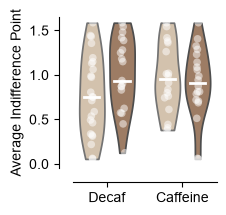

In [27]:
f, ax = plt.subplots(figsize=(2.4, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

session1_decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf' and session == 'session1'")["aveIP"]
session1_decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine' and session == 'session1'")["aveIP"]
session1_caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf' and session == 'session1'")["aveIP"]
session1_caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine' and session == 'session1'")["aveIP"]


colors = ["#1f77b4", "#ff7f0e", "#1f77b4", "#ff7f0e"]
colors = ["#D9C2A7", "#A67B5B", "#D9C2A7", "#A67B5B"]
median_width = 0.3

def make_violinplot(ax, yvals, colors, median_width):

    xvals = [0.7,1.3,2.2,2.8]

    for x, y, c in zip(xvals,
                    yvals,
                    colors):
        sns.violinplot(
        x=x,
        y=y,
        ax=ax,
        color=c,
        width=0.5,
        inner=None,
        native_scale=True,
        alpha=1,
        cut=0
    )
        ax.plot([x-median_width/2, x+median_width/2], [y.median(), y.median()], color="white", linewidth=2)
        
        jitter = np.random.normal(loc=0, scale=0.02, size=len(y))
        ax.scatter([x]*len(y)+jitter, y, alpha=0.5, s=30, edgecolor="none", facecolor="white", linewidth=2)

    ax.set_xticks([1, 2.5], labels=["Decaf", "Caffeine"])

    sns.despine(ax=ax, offset=10)

make_violinplot(ax, yvals=[session1_decaf_decaf,
                           session1_decaf_caf,
                           session1_caf_decaf,
                           session1_caf_caf],
                    colors=colors,
                    median_width=median_width)

ax.set_ylabel("Average Indifference Point")
ax.set_ylim(-0.05, 1.65)
ax.set_yticks([0, 0.5, 1, 1.5])

save_figure_atomic(f, "session1_AIP", FIGSFOLDER)


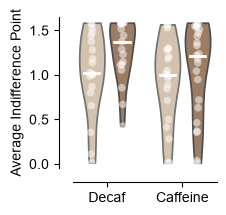

In [29]:
f, ax = plt.subplots(figsize=(2.4, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

session2_decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf' and session == 'session2'")["aveIP"]
session2_decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine' and session == 'session2'")["aveIP"]
session2_caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf' and session == 'session2'")["aveIP"]
session2_caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine' and session == 'session2'")["aveIP"]

make_violinplot(ax, yvals=[session2_decaf_decaf,
                           session2_decaf_caf,
                            session2_caf_decaf,
                            session2_caf_caf],
                    colors=colors,
                    median_width=median_width)

ax.set_ylabel("Average Indifference Point")
ax.set_ylim(-0.05, 1.65)
ax.set_yticks([0, 0.5, 1, 1.5])

save_figure_atomic(f, "session2_AIP", FIGSFOLDER)

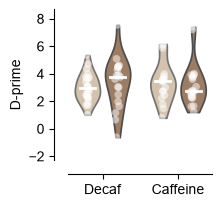

In [30]:
f, ax = plt.subplots(figsize=(2.4, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

column_to_plot = "dprime"

session1_decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf' and session == 'session1'")[column_to_plot]
session1_decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine' and session == 'session1'")[column_to_plot]
session1_caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf' and session == 'session1'")[column_to_plot]
session1_caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine' and session == 'session1'")[column_to_plot]

make_violinplot(ax, yvals=[session1_decaf_decaf,
                           session1_decaf_caf,
                            session1_caf_decaf,
                            session1_caf_caf],
                    colors=colors,
                    median_width=median_width)

ax.set_ylabel("D-prime")
ax.set_ylim(-2.3, 8.7)
ax.set_yticks([-2, 0, 2, 4, 6, 8])

save_figure_atomic(f, "session1_dprime", FIGSFOLDER)

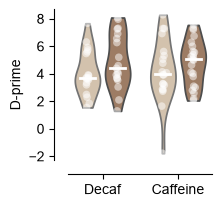

In [31]:
f, ax = plt.subplots(figsize=(2.4, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

column_to_plot = "dprime"

session2_decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf' and session == 'session2'")[column_to_plot]
session2_decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine' and session == 'session2'")[column_to_plot]
session2_caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf' and session == 'session2'")[column_to_plot]
session2_caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine' and session == 'session2'")[column_to_plot]

make_violinplot(ax, yvals=[session2_decaf_decaf,
                           session2_decaf_caf,
                            session2_caf_decaf,
                            session2_caf_caf],
                    colors=colors,
                    median_width=median_width)
ax.set_ylabel("D-prime")
ax.set_ylim(-2.3, 8.7)
ax.set_yticks([-2, 0, 2, 4, 6, 8])

save_figure_atomic(f, "session2_dprime", FIGSFOLDER)

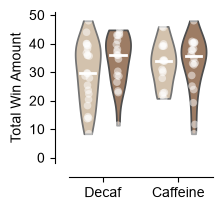

In [32]:
f, ax = plt.subplots(figsize=(2.4, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

column_to_plot = "values.winAmountTotal"

session1_decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf' and session == 'session1'")[column_to_plot]
session1_decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine' and session == 'session1'")[column_to_plot]
session1_caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf' and session == 'session1'")[column_to_plot]
session1_caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine' and session == 'session1'")[column_to_plot]

make_violinplot(ax, yvals=[session1_decaf_decaf,
                           session1_decaf_caf,
                            session1_caf_decaf,
                            session1_caf_caf],
                    colors=colors,
                    median_width=median_width)
ax.set_ylabel("Total Win Amount")
ax.set_ylim(-2, 51)
ax.set_yticks([0, 10, 20, 30, 40, 50])

save_figure_atomic(f, "session1_winamount", FIGSFOLDER)

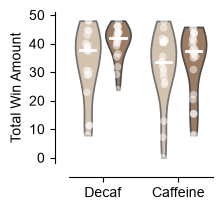

In [33]:
f, ax = plt.subplots(figsize=(2.4, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

column_to_plot = "values.winAmountTotal"

session2_decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf' and session == 'session2'")[column_to_plot]
session2_decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine' and session == 'session2'")[column_to_plot]
session2_caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf' and session == 'session2'")[column_to_plot]
session2_caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine' and session == 'session2'")[column_to_plot]

make_violinplot(ax, yvals=[session2_decaf_decaf,
                           session2_decaf_caf,
                            session2_caf_decaf,
                            session2_caf_caf],
                    colors=colors,
                    median_width=median_width)
ax.set_ylabel("Total Win Amount")
ax.set_ylim(-2, 51)
ax.set_yticks([0, 10, 20, 30, 40, 50])

save_figure_atomic(f, "session2_winamount", FIGSFOLDER)

In [34]:
## redaing in NTLX

result = pyreadr.read_r(DATAFOLDER / "study2_ntnu" / "data" / "ntlx_ntnu.rds")  # also works for RData
df = result[None]  # extract the pandas data frame from the returned dictionary

In [35]:
df

,date,time,group,ID,build,nasatlx7_mentaldemand_response,nasatlx7_mentaldemand_latency,nasatlx7_physicaldemand_response,nasatlx7_physicaldemand_latency,nasatlx7_temporaldemand_response,...,nasatlx7_performance_response,nasatlx7_performance_latency,nasatlx7_effort_response,nasatlx7_effort_latency,nasatlx7_frustration_response,nasatlx7_frustration_latency,X,session,belief,drug
0,102423,09:42:56,90,3007,5.0.14.0,19,29434,5,29434,12,...,11,29434,21,29434,10,29434,NaN,1.0,decaf,caffeine
1,103123,09:39:29,129,3007,5.0.14.0,21,21603,3,21603,11,...,4,21603,20,21603,13,21603,NaN,2.0,caffeine,decaf
2,100323,11:21:23,14,3101,5.0.14.0,15,22647,3,22647,12,...,13,22647,17,22647,11,22647,NaN,1.0,decaf,caffeine
3,101023,11:05:20,56,3101,5.0.14.0,19,23673,3,23673,15,...,10,23673,15,23673,20,23673,NaN,2.0,caffeine,decaf
4,100323,11:22:19,16,3106,5.0.14.0,14,18677,1,18677,16,...,11,18677,14,18677,19,18677,NaN,1.0,decaf,caffeine
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
156,101323,09:26:42,68,6938,5.0.14.0,19,40759,5,40759,11,...,21,40759,18,40759,2,40759,NaN,2.0,caffeine,caffeine
157,100623,09:45:53,28,6942,5.0.14.0,17,27012,1,27012,3,...,3,27012,16,27012,3,27012,NaN,1.0,decaf,decaf
158,101323,09:26:28,66,6942,5.0.14.0,17,21268,1,21268,3,...,19,21268,18,21268,1,21268,NaN,2.0,caffeine,caffeine
159,100623,09:43:46,25,6949,5.0.14.0,4,23164,1,23164,7,...,20,23164,13,23164,6,23164,NaN,1.0,decaf,decaf


In [92]:
df.columns

Index(['date', 'time', 'group', 'ID', 'build',
       'nasatlx7_mentaldemand_response', 'nasatlx7_mentaldemand_latency',
       'nasatlx7_physicaldemand_response', 'nasatlx7_physicaldemand_latency',
       'nasatlx7_temporaldemand_response', 'nasatlx7_temporaldemand_latency',
       'nasatlx7_performance_response', 'nasatlx7_performance_latency',
       'nasatlx7_effort_response', 'nasatlx7_effort_latency',
       'nasatlx7_frustration_response', 'nasatlx7_frustration_latency', 'X',
       'session', 'belief', 'drug'],
      dtype='str')

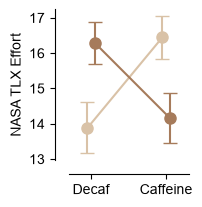

In [37]:
ntlx_col = "nasatlx7_effort_response"

decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf'")[ ntlx_col ]
decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine'")[ ntlx_col ]
caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf'")[ ntlx_col ]
caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine'")[ ntlx_col ]

f, ax = plt.subplots(figsize=(2, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

xvals = np.array([1, 2])
ax.plot(xvals-0.05, [decaf_decaf.mean(), caf_decaf.mean()], color=colors[0], marker="o", markersize=8, label="Decaf belief")
ax.plot(xvals+0.05, [decaf_caf.mean(), caf_caf.mean()], color=colors[1], marker="o", markersize=8, label="Caffeine belief")

ax.errorbar(xvals-0.05, [decaf_decaf.mean(), caf_decaf.mean()], yerr=[decaf_decaf.sem(), caf_decaf.sem()], color=colors[0], fmt="none", capsize=5)
ax.errorbar(xvals+0.05, [decaf_caf.mean(), caf_caf.mean()], yerr=[decaf_caf.sem(), caf_caf.sem()], color=colors[1], fmt="none", capsize=5)

ax.set_xticks(xvals, labels=["Decaf", "Caffeine"])
ax.set_ylabel("NASA TLX Effort")

ax.set_xlim(0.7, 2.3)
ax.set_yticks([13, 14, 15, 16, 17])

sns.despine(ax=ax, offset=10)

save_figure_atomic(f, "ntlx_effort", FIGSFOLDER)


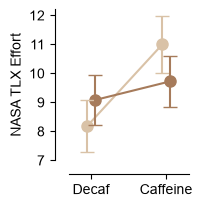

In [38]:
ntlx_col = "nasatlx7_frustration_response"

decaf_decaf = df.query("belief == 'decaf' and drug == 'decaf'")[ ntlx_col ]
decaf_caf = df.query("belief == 'decaf' and drug == 'caffeine'")[ ntlx_col ]
caf_decaf = df.query("belief == 'caffeine' and drug == 'decaf'")[ ntlx_col ]
caf_caf = df.query("belief == 'caffeine' and drug == 'caffeine'")[ ntlx_col ]

f, ax = plt.subplots(figsize=(2, 2.4),
                     gridspec_kw={"left": 0.3, "bottom": 0.25})

xvals = np.array([1, 2])
ax.plot(xvals-0.05, [decaf_decaf.mean(), caf_decaf.mean()], color=colors[0], marker="o", markersize=8, label="Decaf belief")
ax.plot(xvals+0.05, [decaf_caf.mean(), caf_caf.mean()], color=colors[1], marker="o", markersize=8, label="Caffeine belief")

ax.errorbar(xvals-0.05, [decaf_decaf.mean(), caf_decaf.mean()], yerr=[decaf_decaf.sem(), caf_decaf.sem()], color=colors[0], fmt="none", capsize=5)
ax.errorbar(xvals+0.05, [decaf_caf.mean(), caf_caf.mean()], yerr=[decaf_caf.sem(), caf_caf.sem()], color=colors[1], fmt="none", capsize=5)

ax.set_xticks(xvals, labels=["Decaf", "Caffeine"])
ax.set_ylabel("NASA TLX Effort")

ax.set_xlim(0.7, 2.3)
ax.set_yticks([7, 8, 9, 10, 11, 12])

sns.despine(ax=ax, offset=10)

save_figure_atomic(f, "ntlx_frustration", FIGSFOLDER)
